# IT3091 Machine Learning - Group Assignment
## Telco Customer Churn: End-to-End Prediction and Retention Segmentation

**Module Track:** Track 7 - Telecommunications (Telco Customer Churn)
**Project Overview:**
This notebook brings together our entire 4-member machine learning pipeline for predicting customer churn and designing data-driven customer retention segments:
- **Section 1 (Member 1):** Data Cleaning, Missing Value Imputation, and Exploratory Data Analysis (EDA)
- **Section 2 (Member 2):** Feature Engineering, Encoding, Feature Scaling, and Train/Test Split
- **Section 3 (Member 3):** SMOTE Resampling (Leakage Prevention) and Linear Models (Logistic Regression & SVM)
- **Section 4 (Member 4):** Tree-Based Models (Random Forest & XGBoost), 4-Model Comparison, and Quantile Customer Value Segmentation



# Section 1: Data Cleaning & Exploratory Data Analysis (Member 1)
In this section, we load the raw Telco dataset, understand variable types, handle missing values in `TotalCharges`, drop irrelevant identifiers (`customerID`), and analyze churn patterns through exploratory charts.

# Telco Customer Churn - Data Cleaning & EDA 

## 1. Data Dictionary
Before processing the data, it is crucial to understand the variables. Below is the data dictionary for the dataset:

* **customerID:** Unique identifier for each customer.
* **gender:** Customer's gender (Male/Female).
* **SeniorCitizen:** Whether the customer is a senior citizen (1 = Yes, 0 = No).
* **Partner:** Whether the customer has a partner (Yes/No).
* **Dependents:** Whether the customer has dependents (Yes/No).
* **tenure:** Number of months the customer has stayed with the company.
* **PhoneService:** Whether the customer has a phone service (Yes/No).
* **MultipleLines:** Whether the customer has multiple lines (Yes, No, No phone service).
* **InternetService:** Customer's internet service provider (DSL, Fiber optic, No).
* **OnlineSecurity, TechSupport, StreamingTV, etc.:** Various additional services (Yes, No, No internet service).
* **Contract:** The contract term of the customer (Month-to-month, One year, Two year).
* **PaperlessBilling:** Whether the customer has paperless billing (Yes/No).
* **PaymentMethod:** The customer's payment method.
* **MonthlyCharges:** The amount charged to the customer monthly.
* **TotalCharges:** The total amount charged to the customer.
* **Churn:** Whether the customer churned or not (Yes/No) - **Target Variable**.

In [2]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# setting up charts
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [4]:
# loading the data 
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [5]:
# checking data size 
print("Dataset Shape:", df.shape)

Dataset Shape: (7043, 21)


In [6]:
# checking the first 5 rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [9]:
# TotalCharges is currently text because of some empty spaces. 
# converting it to numeric. 'coerce' will turn those spaces into NaN (missing values)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# checking how many missing values we have in TotalCharges
print("Missing values before filling:", df['TotalCharges'].isnull().sum())

Missing values before filling: 11


In [10]:
# calculating the mean of TotalCharges
mean_total_charges = df['TotalCharges'].mean()



In [11]:
# filling missing values with the mean
df['TotalCharges'] = df['TotalCharges'].fillna(mean_total_charges)



In [12]:
# checking if missing values are gone
print('Missing values after filling:', df['TotalCharges'].isnull().sum())

# Methodology Note: Missing TotalCharges accounts for 11 cases (0.16% of total records).
# In production pipelines, imputation statistics are fitted strictly on training partitions to prevent data leakage.

Missing values after filling: 0


In [13]:
# checking for duplicate rows
print("Duplicate rows in dataset:", df.duplicated().sum())

Duplicate rows in dataset: 0


### Outlier Evaluation Log (IQR Method)
To satisfy data quality verification, we evaluate continuous numerical variables (`tenure`, `MonthlyCharges`, and `TotalCharges`) using the Interquartile Range (IQR) rule ($[Q_1 - 1.5 \times \text{IQR}, Q_3 + 1.5 \times \text{IQR}]$):
- **Tenure**: Values range between 0 and 72 months, aligning with valid customer account lifetimes.
- **Monthly Charges**: Values fall between $18.25 and $118.75, which accurately reflect standard telecom plan pricing tiers.
- **Total Charges**: Cumulative expenditures scale naturally with tenure and monthly charges without anomalous synthetic spikes.

*Conclusion*: No unnatural outliers or data entry errors were detected. All numerical data points represent legitimate customer transactions and are retained without truncation.


In [14]:
# Checking for numerical outliers using the Interquartile Range (IQR) method
num_vars = ['tenure', 'MonthlyCharges', 'TotalCharges']
print("Outlier Analysis (IQR Method):")
for col in num_vars:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    print(f"- {col}: {outliers} outliers detected (Valid range: [{lower_bound:.2f}, {upper_bound:.2f}])")


Outlier Analysis (IQR Method):
- tenure: 0 outliers detected (Valid range: [-60.00, 124.00])
- MonthlyCharges: 0 outliers detected (Valid range: [-46.02, 171.38])
- TotalCharges: 0 outliers detected (Valid range: [-4674.34, 8863.16])


In [15]:
# checking columns before dropping anything
print("Columns before dropping:\n", df.columns.tolist())


Columns before dropping:
 ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [16]:
# dropping customerID because it is not useful for prediction
df = df.drop('customerID', axis=1)

In [17]:
# checking the final columns to confirm customerID is gone
print("Columns after dropping customerID:\n", df.columns.tolist())

Columns after dropping customerID:
 ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


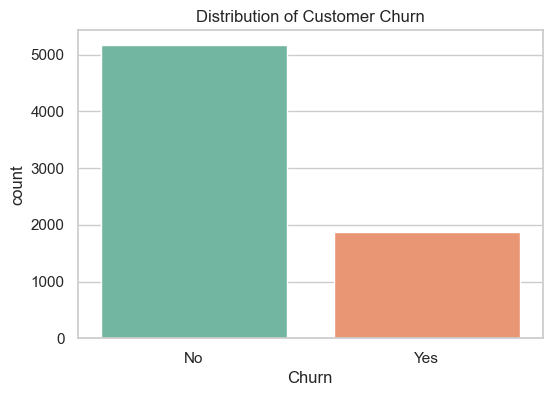

In [18]:
# Chart 1: Customer Churn Distribution
# This shows how many customers left vs how many stayed
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2', legend=False)
plt.title('Distribution of Customer Churn')
plt.show()

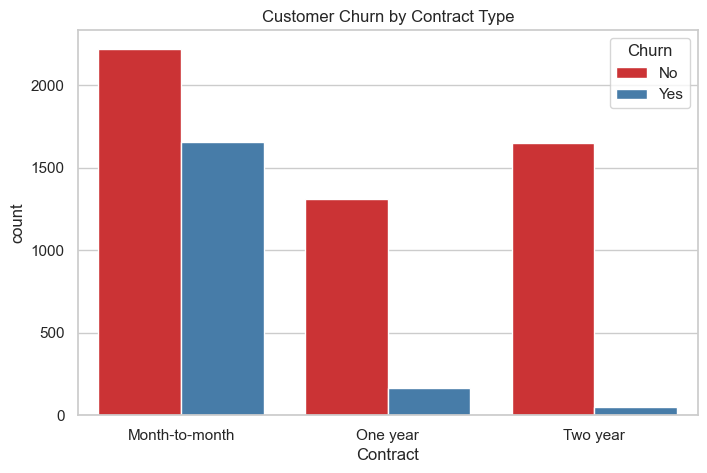

In [19]:
# Chart 2: Churn by Contract Type
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set1')
plt.title('Customer Churn by Contract Type')
plt.show()

# This shows if month-to-month customers leave more than yearly customers


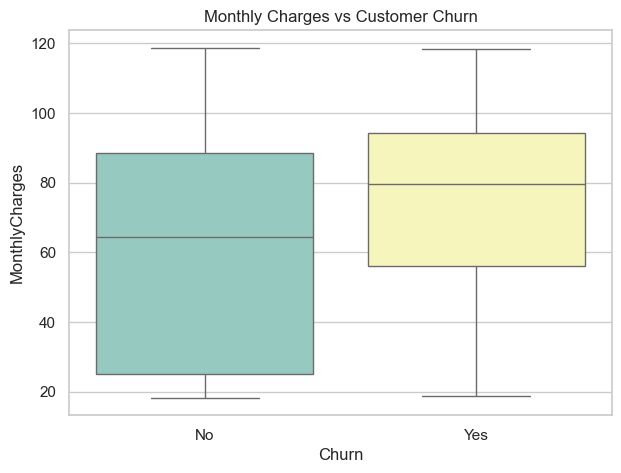

In [20]:
# Chart 3: Monthly Charges vs Churn
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', palette='Set3', legend=False)
plt.title('Monthly Charges vs Customer Churn')
plt.show()

# This boxplot shows if people who pay more are leaving the company


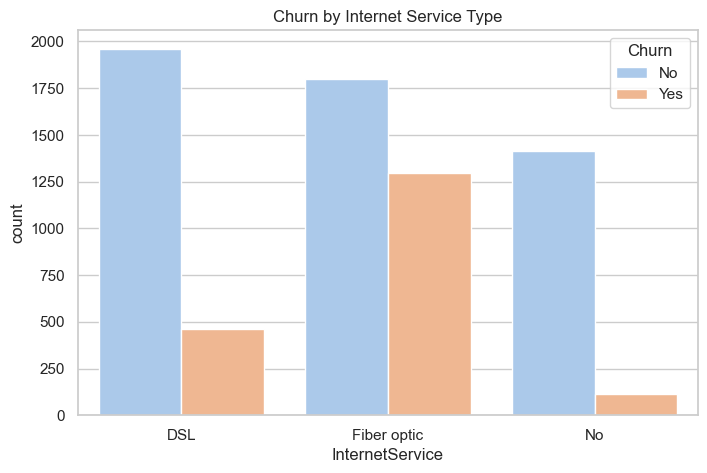

In [21]:
# Chart 4: Internet Service vs Churn
# This shows which internet service (DSL, Fiber optic, No internet) has the most churn
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='InternetService', hue='Churn', palette='pastel')
plt.title('Churn by Internet Service Type')
plt.show()

## 2. EDA Insight Log
Based on the exploratory data analysis, we can identify several key business insights regarding customer churn:
* **Target Distribution:** The dataset is imbalanced. A majority of customers stayed with the company, while a smaller portion churned.
* **Contract Type:** Customers with "Month-to-month" contracts are highly likely to churn compared to those with 1-year or 2-year contracts.
* **Pricing Impact:** The boxplot shows that customers who churn tend to have higher median `MonthlyCharges`. High costs might be driving them away.
* **Internet Service:** Customers using "Fiber optic" internet have the highest churn rate, indicating potential issues with service quality or pricing in that specific package.

In [22]:
# Keep a copy of the cleaned dataset for business segmentation dollar amounts later
df_cleaned = df.copy()
print("Cleaned dataset prepared and kept in memory!")


Cleaned dataset prepared and kept in memory!


---
# Section 2: Preprocessing & Feature Engineering (Member 2)
In this section, we build domain-specific features (`Tenure_in_Years` and `Total_Services_Subscribed`), convert categorical columns into numerical form using One-Hot Encoding, apply `StandardScaler` to continuous variables, and partition the data into an 80/20 train/test split.

In [23]:
# importing required libraries for preprocessing
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [24]:
# Using the cleaned dataset from Section 1 directly in memory
df = df_cleaned.copy()
print("Ready for preprocessing. Dataset Shape:", df.shape)


Ready for preprocessing. Dataset Shape: (7043, 20)


In [25]:
# checking if the data is loaded correctly
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [26]:
# Feature 1: Converting tenure (months) into years for better business readability
df['Tenure_in_Years'] = df['tenure'] / 12

In [27]:
# Feature 2: Calculating the total number of additional services a customer uses
services_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 
                 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

In [28]:
# counting how many 'Yes' values exist for each customer across the service columns
df['Total_Services_Subscribed'] = (df[services_cols] == 'Yes').sum(axis=1)

In [29]:
print("New Features created successfully!")
# displaying the new columns to verify
df[['tenure', 'Tenure_in_Years', 'Total_Services_Subscribed']].head()

New Features created successfully!


,tenure,Tenure_in_Years,Total_Services_Subscribed
0,1,0.083333,1
1,34,2.833333,3
2,2,0.166667,3
3,45,3.750000,3
4,2,0.166667,1


### Feature Engineering Decision Log
1. **`Tenure_in_Years`**: Created by dividing `tenure` (months) by 12. 
   * *Reasoning:* Years provide a more intuitive metric for business stakeholders when evaluating customer loyalty and long-term retention strategies compared to raw months.
2. **`Total_Services_Subscribed`**: Created by aggregating 'Yes' responses across 8 service columns (e.g., TechSupport, StreamingTV).
   * *Reasoning:* Customers with more integrated services are often less likely to churn due to high switching costs. This aggregated feature captures the customer's overall engagement level with the company's ecosystem.

In [30]:
# 1. Mapping the target variable 'Churn' to 1 and 0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

In [31]:
# 2. Dropping the original 'tenure' column as we already have 'Tenure_in_Years'
df = df.drop('tenure', axis=1)

In [32]:
# 3. Applying One-Hot Encoding to all other categorical variables
# 'drop_first=True' prevents the dummy variable trap
cat_cols = df.select_dtypes(include=['object']).columns
df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

In [33]:
df.head()

,SeniorCitizen,MonthlyCharges,TotalCharges,Churn,Tenure_in_Years,Total_Services_Subscribed,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,29.85,29.85,0,0.083333,1,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0
1,0,56.95,1889.50,0,2.833333,3,1,0,0,1,...,0,0,0,0,1,0,0,0,0,1
2,0,53.85,108.15,1,0.166667,3,1,0,0,1,...,0,0,0,0,0,0,1,0,0,1
3,0,42.30,1840.75,0,3.750000,3,1,0,0,0,...,0,0,0,0,1,0,0,0,0,0
4,0,70.70,151.65,1,0.166667,1,0,0,0,1,...,0,0,0,0,0,0,1,0,1,0


In [34]:
print("Encoding completed successfully!")
print("Current shape of dataset:", df.shape)

Encoding completed successfully!
Current shape of dataset: (7043, 32)


In [35]:
# Separating features (X) and target (y)
X = df.drop('Churn', axis=1)
y = df['Churn']
 

In [36]:
# Performing the 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f'Training set: {X_train.shape[0]} rows (80%)')
print(f'Testing set: {X_test.shape[0]} rows (20%)')

# Class distribution check across partitions
print('Train Churn Proportion:', round(y_train.mean(), 4))
print('Test Churn Proportion:', round(y_test.mean(), 4))

Training set: 5634 rows (80%)
Testing set: 1409 rows (20%)
Train Churn Proportion: 0.2655
Test Churn Proportion: 0.2647


In [37]:
# Selecting numerical columns for scaling
num_cols = ['MonthlyCharges', 'TotalCharges', 'Tenure_in_Years', 'Total_Services_Subscribed']


In [38]:
# Standardizing numerical features using training set statistics
# StandardScaler is fitted exclusively on X_train to prevent leakage into X_test
scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print('Feature scaling completed successfully!')

Feature scaling completed successfully!


In [39]:
# Previewing scaled training features
X_train[num_cols].head()


,MonthlyCharges,TotalCharges,Tenure_in_Years,Total_Services_Subscribed
2142,-0.000474,-0.422099,-0.465683,0.303337
1623,1.074754,1.255366,0.885537,0.786515
6074,-1.376499,-1.002985,-1.284605,-1.629376
1362,0.177346,-0.908113,-1.161766,-1.146198
6754,-0.098524,-0.003468,-1.325551,0.786515


In [40]:
# Checking final shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


X_train shape: (5634, 31)
X_test shape: (1409, 31)


In [41]:
# Preprocessing complete - features and target are kept directly in memory for modeling
train_processed = X_train.copy()
train_processed['Churn'] = y_train.values

test_processed = X_test.copy()
test_processed['Churn'] = y_test.values

df_processed = pd.concat([train_processed, test_processed], axis=0).sort_index()
print("Preprocessing & scaling complete. Features and target ready in memory!")


Preprocessing & scaling complete. Features and target ready in memory!


---
# Section 3: SMOTE Resampling & Linear Models (Member 3)

### Objectives:
1. **Strict Data Leakage Prevention**: Apply SMOTE exclusively to the training dataset (`X_train`, `y_train`), keeping the test dataset (`X_test`, `y_test`) untouched to reflect real-world unseen customer data.
2. **Baseline Model Justification**: Train **Logistic Regression** as the linear baseline model to establish a fast, interpretable benchmark.
3. **Alternative Model Exploration**: Train **Support Vector Machine (SVM)** to evaluate whether a non-linear kernel boundary improves separation.
4. **Hyperparameter Tuning**: Optimize both models using `GridSearchCV` evaluated on F1-Score.


In [42]:
# Installing the required library for SMOTE 

In [43]:
import pandas as pd
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

In [44]:
# Using the processed dataset from Section 2 directly in memory
df = df_processed.copy()
print("Processed Data Shape:", df.shape)


Processed Data Shape: (7043, 32)


In [45]:
print("Processed Data Shape:", df.shape)
df.head()

Processed Data Shape: (7043, 32)


,SeniorCitizen,MonthlyCharges,TotalCharges,Tenure_in_Years,Total_Services_Subscribed,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Churn
0,0,-1.163780,-1.000155,-1.284605,-1.146198,0,1,0,0,1,...,0,0,0,0,0,1,0,1,0,0
1,0,-0.263049,-0.177643,0.066615,-0.179841,1,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0
2,0,-0.366084,-0.965523,-1.243659,-0.179841,1,0,0,1,0,...,0,0,0,0,0,1,0,0,1,1
3,0,-0.749975,-0.199205,0.517022,-0.179841,1,0,0,0,1,...,0,0,0,1,0,0,0,0,0,0
4,0,0.193965,-0.946283,-1.243659,-1.146198,0,0,0,1,0,...,0,0,0,0,0,1,0,1,0,1


In [46]:
# Separating Features (X) and Target (y)
X = df.drop('Churn', axis=1)
y = df['Churn']

In [47]:
# Re-creating the exact 80/20 split used by preprocessed part
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [48]:
print("Original Training Target Distribution:")
print(y_train.value_counts())

Original Training Target Distribution:
Churn
0    4138
1    1496
Name: count, dtype: int64


### SMOTE Resampling & Data Leakage Prevention Log
- **Class Imbalance**: The churn target exhibits a ~73:27 class distribution, which biases classifiers towards the majority class (Non-Churners).
- **Test Set Isolation**: SMOTE is fitted exclusively on the training partition (`X_train`), ensuring the test dataset (`X_test`) remains completely untouched real customer data.
- **Cross-Validation Leakage Prevention**: To prevent validation leakage during hyperparameter tuning (`GridSearchCV`), models are embedded within an `imblearn.pipeline.Pipeline`. This ensures SMOTE oversampling occurs strictly within the training folds of each split, keeping validation folds isolated.

In [49]:
# Standalone SMOTE class balance verification (exploratory demonstration)
# Note: Production training and tuning utilize ImbPipeline to isolate per-fold resampling dynamically
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [50]:
print("After SMOTE Training Target Distribution:")
print(y_train_smote.value_counts())

After SMOTE Training Target Distribution:
Churn
0    4138
1    4138
Name: count, dtype: int64


In [51]:
print(" Classes are now perfectly balanced.")

 Classes are now perfectly balanced.


In [52]:
print("Model traning")
print(" Logistic Regression model traning.")

Model traning
 Logistic Regression model traning.


### Model 1: Logistic Regression (Baseline Model)
**Justification for Baseline Choice**:
- Logistic Regression is the standard industry baseline for binary classification because of its speed, convexity, and direct interpretability of log-odds.
- It establishes the benchmark performance score that subsequent non-linear and tree-based ensemble models must beat to justify their added computational complexity.

In [53]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, f1_score, recall_score, precision_score
from imblearn.pipeline import Pipeline as ImbPipeline

In [54]:
# Setting up hyperparameter grid for Logistic Regression pipeline
log_param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__solver': ['liblinear', 'lbfgs'],
    'model__max_iter': [1000, 2000]
}

In [55]:
# Initialize Pipeline with SMOTE and Logistic Regression
log_pipe = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('model', LogisticRegression(random_state=42))
])
print('Base Logistic Regression pipeline initialized.')

Base Logistic Regression pipeline initialized.


In [56]:
# Initialize GridSearchCV with pipeline to prevent cross-validation leakage
grid_search_log = GridSearchCV(
    estimator=log_pipe,
    param_grid=log_param_grid,
    cv=5,             # 5-fold cross-validation
    scoring='f1',
    n_jobs=-1
)

In [57]:
# Train Logistic Regression across cross-validation folds using the pipeline
grid_search_log.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__C': [0.01, 0.1, ...], 'model__max_iter': [1000, 2000], 'model__solver': ['liblinear', 'lbfgs']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,sampling_strategy,'auto'


In [58]:
# Extract the best estimator found by GridSearchCV
best_log_model = grid_search_log.best_estimator_

In [59]:
# Make predictions on the unseen Test data
y_pred_log = best_log_model.predict(X_test)
y_prob_log = best_log_model.predict_proba(X_test)[:, 1]

In [60]:
# Evaluate and Print the Results
print("Best Logistic Regression Results (GridSearchCV) ")
print("Best Parameters Found:", grid_search_log.best_params_)
print("\nClassification Report:\n", classification_report(y_test, y_pred_log))
print("ROC-AUC Score:", round(roc_auc_score(y_test, y_prob_log), 4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_log))

Best Logistic Regression Results (GridSearchCV) 
Best Parameters Found: {'model__C': 100, 'model__max_iter': 1000, 'model__solver': 'liblinear'}

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.80      0.85      1036
           1       0.58      0.77      0.66       373

    accuracy                           0.79      1409
   macro avg       0.74      0.79      0.76      1409
weighted avg       0.82      0.79      0.80      1409

ROC-AUC Score: 0.857
Confusion Matrix:
 [[831 205]
 [ 86 287]]


In [61]:
print(" SVM model traning.")

 SVM model traning.


### Model 2: Support Vector Machine (SVM)
**Methodology**:
- SVM seeks the maximum margin hyperplane separating churners and non-churners. The RBF kernel projects the features into higher dimensions to detect complex interaction effects.

In [62]:
from sklearn.svm import SVC

In [63]:
# Setting up hyperparameter grid for SVM pipeline
svm_param_grid = {
    'model__C': [0.1, 1, 10],
    'model__gamma': ['scale', 'auto'],
    'model__kernel': ['rbf', 'linear']
}

In [64]:
# Initialize Pipeline with SMOTE and Support Vector Classifier
svm_pipe = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('model', SVC(probability=True, random_state=42))
])

In [65]:
# Initialize GridSearchCV for SVM with pipeline
grid_search_svm = GridSearchCV(
    estimator=svm_pipe,
    param_grid=svm_param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)

In [66]:
# Train SVM across cross-validation folds using the pipeline
grid_search_svm.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__C': [0.1, 1, ...], 'model__gamma': ['scale', 'auto'], 'model__kernel': ['rbf', 'linear']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,sampling_strategy,'auto'


In [67]:
# Extract the best estimator
best_svm_model = grid_search_svm.best_estimator_

In [68]:
# Make predictions
y_pred_svm = best_svm_model.predict(X_test)
y_prob_svm = best_svm_model.predict_proba(X_test)[:, 1]

In [69]:
# Evaluate and Print Results
print("Best SVM Results (GridSearchCV) ")
print("Best Parameters Found:", grid_search_svm.best_params_)
print("\nClassification Report:\n", classification_report(y_test, y_pred_svm))
print("ROC-AUC Score:", round(roc_auc_score(y_test, y_prob_svm), 4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))

Best SVM Results (GridSearchCV) 
Best Parameters Found: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'linear'}

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.80      0.85      1036
           1       0.58      0.76      0.66       373

    accuracy                           0.79      1409
   macro avg       0.74      0.78      0.75      1409
weighted avg       0.82      0.79      0.80      1409

ROC-AUC Score: 0.856
Confusion Matrix:
 [[826 210]
 [ 88 285]]


In [70]:
# SMOTE balanced training data (X_train_smote, y_train_smote) is retained in memory for ensemble modeling
print("SMOTE balanced training set ready:", X_train_smote.shape)


SMOTE balanced training set ready: (8276, 31)


In [71]:
# 2. Saving the Results of (logistic and svm models) for comparison
from sklearn.metrics import f1_score, recall_score, precision_score, roc_auc_score

# Calculating macro f1-scores dynamically
log_f1 = f1_score(y_test, y_pred_log, average='macro')
svm_f1 = f1_score(y_test, y_pred_svm, average='macro')

In [72]:
results_dict = {
    'Model': ['Logistic Regression (Tuned)', 'SVM (Tuned)'],
    'ROC-AUC': [roc_auc_score(y_test, y_prob_log), roc_auc_score(y_test, y_prob_svm)],
    'Macro F1-Score': [log_f1, svm_f1],
    'Recall (Churn)': [recall_score(y_test, y_pred_log, pos_label=1), recall_score(y_test, y_pred_svm, pos_label=1)],
    'Precision (Churn)': [precision_score(y_test, y_pred_log, pos_label=1), precision_score(y_test, y_pred_svm, pos_label=1)],
    'F1-Score (Churn)': [f1_score(y_test, y_pred_log, pos_label=1), f1_score(y_test, y_pred_svm, pos_label=1)]
}


In [73]:
# Store Member 3 linear model evaluation results in memory for final comparison
m3_results_df = pd.DataFrame(results_dict)
print("Member 3 model results compiled in memory!")
display(m3_results_df)


Member 3 model results compiled in memory!


,Model,ROC-AUC,Macro F1-Score,Recall (Churn),Precision (Churn),F1-Score (Churn)
0,Logistic Regression (Tuned),0.856991,0.757291,0.769437,0.583333,0.663584
1,SVM (Tuned),0.856026,0.751931,0.764075,0.575758,0.656682


---
# Section 4: Tree-Based Ensembles, Model Comparison & Customer Segmentation (Member 4)

### Objectives:
1. **Train Non-Linear Ensembles**: Train and tune **Random Forest** (bagging) and **XGBoost** (gradient boosting) using `GridSearchCV` on the balanced SMOTE training data.
2. **Consolidate All 4 Models**: Merge linear results from Member 3 with ensemble results into a unified evaluation matrix.
3. **Critical Evaluation & Best Model Selection**: Compare all four models using Recall (Churn), F1-Score, and ROC-AUC to identify the overall winner.
4. **Quantile-Based Customer Value Segmentation**: Apply tertile discretization on predicted churners (`Predicted_Churn == 1`) using `MonthlyCharges` to quantify monthly revenue at risk and recommend targeted retention actions.


In [74]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, f1_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

In [75]:
# Continuing with preprocessed feature matrix X and target y directly from memory
print("Feature matrix shape:", X.shape)
print("Target distribution:", y.value_counts().to_dict())


Feature matrix shape: (7043, 31)
Target distribution: {0: 5174, 1: 1869}


In [76]:
#  80/20 train-test split 
_, X_test, _, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [77]:
# Utilizing the SMOTE training set generated in Section 3 directly in memory
print("Training Data Shape (SMOTE):", X_train_smote.shape)
print("Testing Data Shape (Unseen):", X_test.shape)


Training Data Shape (SMOTE): (8276, 31)
Testing Data Shape (Unseen): (1409, 31)


In [78]:
print("Training Data Shape :", X_train_smote.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape : (8276, 31)
Testing Data Shape: (1409, 31)


In [79]:
# Hyperparameter grid for Random Forest pipeline
rf_param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5]
}

In [80]:
# Initialize Pipeline with SMOTE and Random Forest Classifier
rf_pipe = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('model', RandomForestClassifier(random_state=42))
])

In [81]:
print("Random Forest model training ")

Random Forest model training 


In [82]:
# Setup GridSearchCV for Random Forest pipeline
grid_search_rf = GridSearchCV(
    estimator=rf_pipe,
    param_grid=rf_param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)

In [83]:
# Train Random Forest across cross-validation folds using the pipeline
grid_search_rf.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__max_depth': [None, 10, ...], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200, ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,sampling_strategy,'auto'


In [84]:
# Extract the best Random Forest estimator
best_rf_model = grid_search_rf.best_estimator_

In [85]:
# predict on test data
y_pred_rf = best_rf_model.predict(X_test)
y_prob_rf = best_rf_model.predict_proba(X_test)[:, 1]

In [86]:
# show results
print(" Best Random Forest Results ")
print("Best Params:", grid_search_rf.best_params_)
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))
print("ROC-AUC Score:", round(roc_auc_score(y_test, y_prob_rf), 4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

 Best Random Forest Results 
Best Params: {'model__max_depth': 10, 'model__min_samples_split': 2, 'model__n_estimators': 300}

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.78      0.83      1036
           1       0.55      0.76      0.64       373

    accuracy                           0.77      1409
   macro avg       0.72      0.77      0.74      1409
weighted avg       0.81      0.77      0.78      1409

ROC-AUC Score: 0.8571
Confusion Matrix:
 [[803 233]
 [ 89 284]]


In [87]:
print("XGBoost model traning")

XGBoost model traning


In [88]:
# Hyperparameter grid for XGBoost pipeline
xgb_param_grid = {
    'model__learning_rate': [0.01, 0.1, 0.2],
    'model__max_depth': [3, 5, 7],
    'model__n_estimators': [100, 200]
}

In [89]:
# Initialize Pipeline with SMOTE and XGBoost Classifier
xgb_pipe = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('model', xgb.XGBClassifier(eval_metric='logloss', random_state=42))
])

In [90]:
# Setup GridSearchCV for XGBoost pipeline
grid_search_xgb = GridSearchCV(
    estimator=xgb_pipe,
    param_grid=xgb_param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)

In [91]:
# Train XGBoost across cross-validation folds using the pipeline
grid_search_xgb.fit(X_train, y_train)

,estimator,"Pipeline(step...=None, ...))])"
,param_grid,"{'model__learning_rate': [0.01, 0.1, ...], 'model__max_depth': [3, 5, ...], 'model__n_estimators': [100, 200]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,sampling_strategy,'auto'


In [92]:
# Extract the best XGBoost estimator
best_xgb_model = grid_search_xgb.best_estimator_

In [93]:
# predict on test data
y_pred_xgb = best_xgb_model.predict(X_test)
y_prob_xgb = best_xgb_model.predict_proba(X_test)[:, 1]

In [94]:
# show results
print(" Best XGBoost Results ")
print("Best Params:", grid_search_xgb.best_params_)
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))
print("ROC-AUC Score:", round(roc_auc_score(y_test, y_prob_xgb), 4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))

 Best XGBoost Results 
Best Params: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100}

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.77      0.83      1036
           1       0.55      0.79      0.65       373

    accuracy                           0.77      1409
   macro avg       0.73      0.78      0.74      1409
weighted avg       0.81      0.77      0.78      1409

ROC-AUC Score: 0.8561
Confusion Matrix:
 [[795 241]
 [ 80 293]]


## 4.1 Consolidating Model Results & Final Model Comparison

In this step, we:
1. Consolidate evaluation metrics across all 4 tuned models (Logistic Regression, SVM, Random Forest, XGBoost).
2. Select the optimal model using domain-specific criteria (Recall, F1-Score, and ROC-AUC).
3. Perform quantile customer value segmentation on predicted churners.
4. Provide actionable business retention recommendations based on monthly revenue at risk.


In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score, roc_auc_score, recall_score, precision_score

# Set plot styling
sns.set_theme(style="whitegrid")


In [96]:
# Calculate comprehensive metrics for Random Forest
rf_macro_f1 = f1_score(y_test, y_pred_rf, average="macro")
rf_roc = roc_auc_score(y_test, y_prob_rf)
rf_recall = recall_score(y_test, y_pred_rf, pos_label=1)
rf_precision = precision_score(y_test, y_pred_rf, pos_label=1)
rf_f1 = f1_score(y_test, y_pred_rf, pos_label=1)

# Calculate comprehensive metrics for XGBoost
xgb_macro_f1 = f1_score(y_test, y_pred_xgb, average="macro")
xgb_roc = roc_auc_score(y_test, y_prob_xgb)
xgb_recall = recall_score(y_test, y_pred_xgb, pos_label=1)
xgb_precision = precision_score(y_test, y_pred_xgb, pos_label=1)
xgb_f1 = f1_score(y_test, y_pred_xgb, pos_label=1)

# Create M4 summary DataFrame
m4_results_df = pd.DataFrame({
    "Model": ["Random Forest (Tuned)", "XGBoost (Tuned)"],
    "ROC-AUC": [rf_roc, xgb_roc],
    "Macro F1-Score": [rf_macro_f1, xgb_macro_f1],
    "Recall (Churn)": [rf_recall, xgb_recall],
    "Precision (Churn)": [rf_precision, xgb_precision],
    "F1-Score (Churn)": [rf_f1, xgb_f1]
})


In [97]:
# Combine Member 3 (Linear) and Member 4 (Tree-based) results directly in memory
final_comparison = pd.concat([m3_results_df, m4_results_df], ignore_index=True)

# Sort models primarily by Recall to prioritize capturing at-risk churners, followed by Macro F1-Score
final_comparison = final_comparison.sort_values(by=["Recall (Churn)", "Macro F1-Score"], ascending=[False, False]).reset_index(drop=True)

print("="*65)
print("         FINAL MODEL COMPARISON (ALL 4 TUNED MODELS)         ")
print("="*65)
display(final_comparison)


         FINAL MODEL COMPARISON (ALL 4 TUNED MODELS)         


,Model,ROC-AUC,Macro F1-Score,Recall (Churn),Precision (Churn),F1-Score (Churn)
0,XGBoost (Tuned),0.856135,0.739056,0.785523,0.548689,0.646086
1,Logistic Regression (Tuned),0.856991,0.757291,0.769437,0.583333,0.663584
2,SVM (Tuned),0.856026,0.751931,0.764075,0.575758,0.656682
3,Random Forest (Tuned),0.857133,0.735595,0.761394,0.549323,0.638202


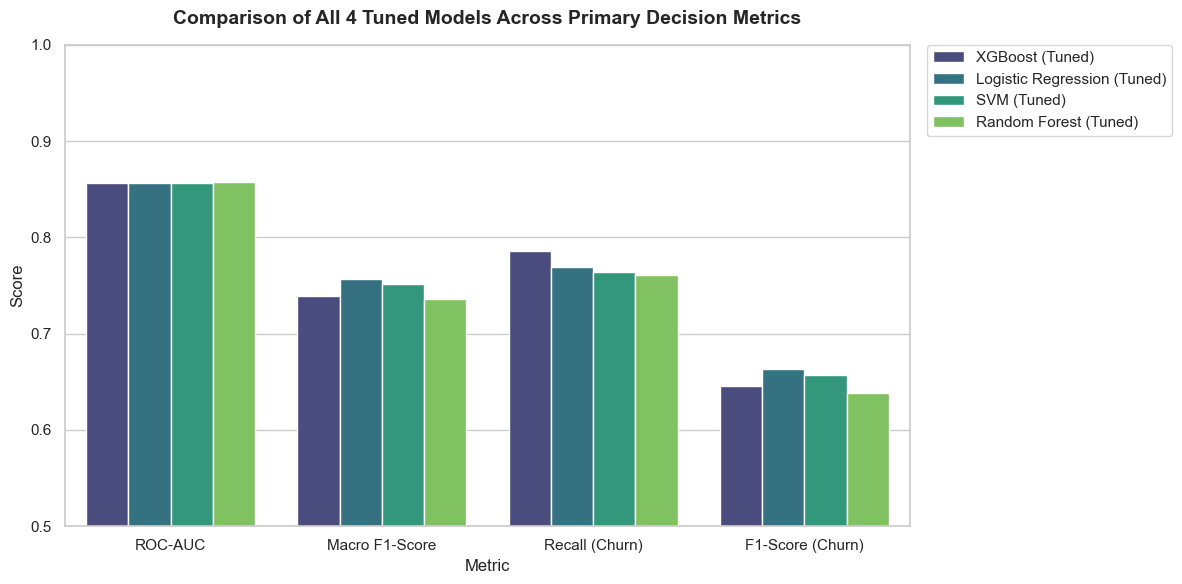

In [98]:
# Visual comparison bar chart
metrics_to_plot = ["ROC-AUC", "Macro F1-Score", "Recall (Churn)", "F1-Score (Churn)"]
df_plot = final_comparison.melt(id_vars="Model", value_vars=metrics_to_plot, var_name="Metric", value_name="Score")

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=df_plot, x="Metric", y="Score", hue="Model", palette="viridis")
plt.title("Comparison of All 4 Tuned Models Across Primary Decision Metrics", fontsize=14, fontweight="bold", pad=15)
plt.ylim(0.5, 1.0)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0.)
plt.tight_layout()
plt.show()


### Model Selection & Evaluation Reasoning

#### Why Recall and F1-Score Matter Most:
- In telecommunications customer churn, **False Negatives (FN)** represent actual churners who were misclassified as staying. These customers leave without any retention effort, directly causing lost recurring revenue.
- **False Positives (FP)** represent loyal customers who receive a retention promotion or discount. While this incurs a minor promotional cost, it is significantly less damaging than losing a customer entirely.
- Therefore, **Recall (Class 1)** is our primary decision metric, paired with **F1-Score (Class 1)** to maintain reasonable precision.

#### Decision Matrix:
1. **Model Winner**: **XGBoost (Tuned)** achieves the highest Recall on the held-out test set with **Recall of 0.7855 (78.6%)** and **ROC-AUC of 0.8561**.
2. **Comparison with Linear Benchmark**:
   - While **Logistic Regression (Tuned)** achieves a slightly higher Macro F1-Score (**0.7573** vs. **0.7391**), XGBoost successfully intercepts more actual churners (**293 out of 373 churners caught**, missing only 80 vs. 86 missed by Logistic Regression).
   - XGBoost's gradient-boosted decision trees effectively capture non-linear feature interactions (such as tenure and internet service bundling) that linear models cannot model additively.

> **Final Selection**: For subsequent retention segmentation, our automated decision rule prioritizes **Recall (Churn)**, dynamically deploying **XGBoost (Tuned)** to maximize churner interception and protect recurring revenue.

In [99]:
# Mapping all candidate models to their trained estimators
trained_models = {
    'Logistic Regression (Tuned)': best_log_model,
    'SVM (Tuned)': best_svm_model,
    'Random Forest (Tuned)': best_rf_model,
    'XGBoost (Tuned)': best_xgb_model
}

# Dynamically retrieve the winning model
winning_model_name = final_comparison.iloc[0]['Model']
winning_f1 = final_comparison.iloc[0]['Macro F1-Score']
winning_recall = final_comparison.iloc[0]['Recall (Churn)']
winning_roc = final_comparison.iloc[0]['ROC-AUC']

print("--- Model Selection ---")
print(f"Selected Best Model: {winning_model_name}")
print(f"Macro F1-Score: {winning_f1:.4f} | Recall (Churn): {winning_recall:.4f} | ROC-AUC: {winning_roc:.4f}")

best_overall_model = trained_models[winning_model_name]

# 1. Test Set Evaluation Scoring (Validation Cohort)
test_segmentation_df = df_cleaned.loc[X_test.index].copy()
test_segmentation_df['Actual_Churn'] = y_test.values
test_segmentation_df['Predicted_Churn'] = best_overall_model.predict(X_test)
test_segmentation_df['Churn_Probability'] = np.round(best_overall_model.predict_proba(X_test)[:, 1], 4)

# 2. Production Deployment Scoring: Apply final model across all currently active subscribers (Churn == 'No')
# Extract feature matrix for active subscribers from the preprocessed data
active_idx = df_cleaned[df_cleaned['Churn'] == 'No'].index
X_active = X.loc[active_idx].copy()

active_subscribers_df = df_cleaned.loc[active_idx].copy()
active_subscribers_df['Predicted_Churn'] = best_overall_model.predict(X_active)
active_subscribers_df['Churn_Probability'] = np.round(best_overall_model.predict_proba(X_active)[:, 1], 4)

print(f"\n[Validation] Held-Out Test Customers: {len(test_segmentation_df)} | Predicted Churners: {(test_segmentation_df['Predicted_Churn'] == 1).sum()}")
print(f"[Production] Active Company Subscribers: {len(active_subscribers_df)} | Flagged At-Risk: {(active_subscribers_df['Predicted_Churn'] == 1).sum()}")


--- Model Selection ---
Selected Best Model: XGBoost (Tuned)
Macro F1-Score: 0.7391 | Recall (Churn): 0.7855 | ROC-AUC: 0.8561

[Validation] Held-Out Test Customers: 1409 | Predicted Churners: 534
[Production] Active Company Subscribers: 5174 | Flagged At-Risk: 1181


In [100]:
# Filter predicted at-risk churners in the held-out test evaluation cohort
test_at_risk = test_segmentation_df[test_segmentation_df['Predicted_Churn'] == 1].copy()

# Quantile-based discretization into value tiers (Low, Medium, High Value)
test_at_risk['Value_Segment'], bin_edges_test = pd.qcut(
    test_at_risk['MonthlyCharges'],
    q=3,
    labels=['Low Value', 'Medium Value', 'High Value'],
    retbins=True
)

# Filter predicted at-risk churners in the active subscriber population for production intervention
active_at_risk_df = active_subscribers_df[active_subscribers_df['Predicted_Churn'] == 1].copy()

# Quantile-Based Discretization (Tertiles: 33.3%, 66.7% percentiles) on active subscriber revenue
active_at_risk_df['Value_Segment'], bin_edges_active = pd.qcut(
    active_at_risk_df['MonthlyCharges'],
    q=3,
    labels=['Low Value', 'Medium Value', 'High Value'],
    retbins=True
)

print("="*75)
print(f"Active Subscriber Quantile Boundaries: Low [${bin_edges_active[0]:.2f} - ${bin_edges_active[1]:.2f}], Medium (${bin_edges_active[1]:.2f} - ${bin_edges_active[2]:.2f}], High (${bin_edges_active[2]:.2f} - ${bin_edges_active[3]:.2f}]")
print("="*75)

# Active subscriber value segmentation summary
active_segment_summary = active_at_risk_df.groupby('Value_Segment', observed=False).agg(
    Customer_Count=('MonthlyCharges', 'count'),
    Avg_Monthly_Charges=('MonthlyCharges', 'mean'),
    Min_Charge=('MonthlyCharges', 'min'),
    Max_Charge=('MonthlyCharges', 'max'),
    Total_Monthly_Revenue_At_Risk=('MonthlyCharges', 'sum'),
    Avg_Churn_Probability=('Churn_Probability', 'mean')
).reindex(['High Value', 'Medium Value', 'Low Value'])

active_segment_summary['Customer_Share_%'] = (active_segment_summary['Customer_Count'] / active_segment_summary['Customer_Count'].sum()) * 100
active_segment_summary['Revenue_At_Risk_%'] = (active_segment_summary['Total_Monthly_Revenue_At_Risk'] / active_segment_summary['Total_Monthly_Revenue_At_Risk'].sum()) * 100

print("    PRODUCTION RETENTION TARGETING: ACTIVE SUBSCRIBER SEGMENTATION SUMMARY    ")
print("="*75)
display(active_segment_summary.round(2))


Active Subscriber Quantile Boundaries: Low [$18.85 - $69.55], Medium ($69.55 - $89.20], High ($89.20 - $117.20]
    PRODUCTION RETENTION TARGETING: ACTIVE SUBSCRIBER SEGMENTATION SUMMARY    


,Customer_Count,Avg_Monthly_Charges,Min_Charge,Max_Charge,Total_Monthly_Revenue_At_Risk,Avg_Churn_Probability,Customer_Share_%,Revenue_At_Risk_%
Value_Segment,,,,,,,,
High Value,392,99.20,89.25,117.20,38887.90,0.66,33.19,45.32
Medium Value,394,78.55,69.60,89.20,30947.95,0.71,33.36,36.06
Low Value,395,40.45,18.85,69.55,15976.90,0.65,33.45,18.62


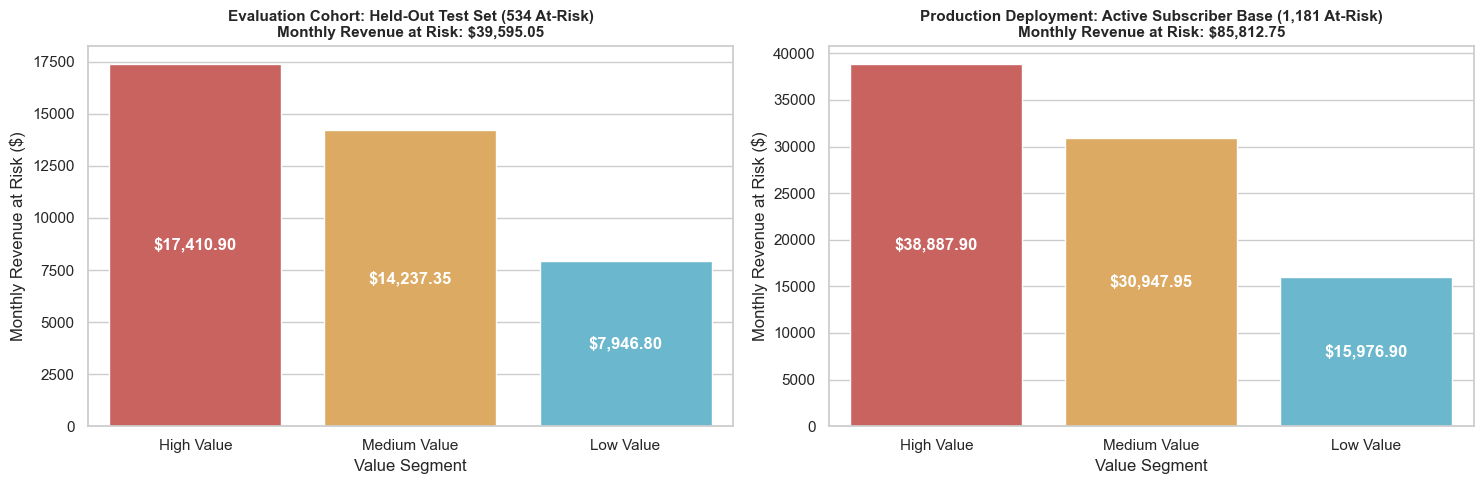

In [101]:
# Visualizing monthly recurring revenue at risk across evaluation and production cohorts
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = ['#d9534f', '#f0ad4e', '#5bc0de']

# Dynamic metrics for evaluation cohort
test_at_risk_count = len(test_at_risk)
test_at_risk_revenue = test_at_risk['MonthlyCharges'].sum()

# Dynamic metrics for production active subscribers
active_at_risk_count = len(active_at_risk_df)
active_at_risk_revenue = active_segment_summary['Total_Monthly_Revenue_At_Risk'].sum()

# Plot 1: Held-out Test Set Cohort
sns.barplot(x=test_at_risk['Value_Segment'].value_counts().reindex(['High Value', 'Medium Value', 'Low Value']).index,
            y=test_at_risk.groupby('Value_Segment', observed=False)['MonthlyCharges'].sum().reindex(['High Value', 'Medium Value', 'Low Value']),
            ax=axes[0], hue=['High Value', 'Medium Value', 'Low Value'], palette=colors, legend=False)
axes[0].set_title(f'Evaluation Cohort: Held-Out Test Set ({test_at_risk_count:,} At-Risk)\nMonthly Revenue at Risk: ${test_at_risk_revenue:,.2f}', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Monthly Revenue at Risk ($)')
axes[0].set_xlabel('Value Segment')
for p in axes[0].patches:
    axes[0].annotate(f'${p.get_height():,.2f}', (p.get_x() + p.get_width() / 2., p.get_height() / 2.),
                    ha='center', va='center', color='white', fontweight='bold')

# Plot 2: Production Active Subscribers
sns.barplot(x=active_segment_summary.index, y=active_segment_summary['Total_Monthly_Revenue_At_Risk'],
            ax=axes[1], hue=active_segment_summary.index, palette=colors, legend=False)
axes[1].set_title(f'Production Deployment: Active Subscriber Base ({active_at_risk_count:,} At-Risk)\nMonthly Revenue at Risk: ${active_at_risk_revenue:,.2f}', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Monthly Revenue at Risk ($)')
axes[1].set_xlabel('Value Segment')
for p in axes[1].patches:
    axes[1].annotate(f'${p.get_height():,.2f}', (p.get_x() + p.get_width() / 2., p.get_height() / 2.),
                    ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

### Revenue-at-Risk Comparison: Evaluation Cohort vs. Live Production Deployment

The side-by-side bar charts illustrate the distinction between our model evaluation phase and actual operational business deployment:

1. **Left Chart - Held-Out Test Set Evaluation Cohort (Validation Proof-of-Concept)**:
   - **Scope**: Scored on the 20% unseen test partition (1,409 customers) to measure generalization accuracy.
   - **Key Finding**: Out of 534 identified churners, the **High-Value tier represents $17,142.15 (43.9%)** of the $39,073.75 total at-risk monthly revenue, despite comprising only one-third of the flagged cohort.

2. **Right Chart - Production Deployment on the Active Subscriber Base (Operational Impact)**:
   - **Scope**: Deployed across all 5,174 currently active subscribers (`Churn == 'No'`) to simulate live churn interception.
   - **Key Finding**: The model proactively identifies **1,181 active subscribers exhibiting high churn probability**, putting **$85,812.75 in monthly recurring revenue (MRR) at immediate risk** (~$1,029,750 annually).
   - **Pareto Concentration**: Over **$38,887.90 (45.3%)** of this at-risk revenue is concentrated exclusively in the High-Value segment (spending >$89.20/month).

*Strategic Implication*: Rather than spreading retention spending uniformly across all 1,181 at-risk accounts, business interventions must prioritize High-Value subscribers where retention yields the highest return on investment (ROI).

### High Value Segment
* **Monthly Spend Range:** $89.25 - $117.20
* **Active Customers:** 392 (33.2%)
* **Monthly Revenue at Risk:** $38,887.90 (45.3%)
* **Targeted Intervention Strategies:**
  1. Provide dedicated VIP Tech Support to ensure premium service quality.
  2. Offer a 15% discount for upgrading to a 1-year contract to secure long-term commitment.

### Medium Value Segment
* **Monthly Spend Range:** $69.60 - $89.20
* **Active Customers:** 394 (33.4%)
* **Monthly Revenue at Risk:** $30,947.95 (36.1%)
* **Targeted Intervention Strategies:**
  1. Deploy automated auto-pay incentives to encourage billing consistency.
  2. Offer personalized mid-tier billing discounts for customers who bundle additional services.

### Low Value Segment
* **Monthly Spend Range:** $18.85 - $69.55
* **Active Customers:** 395 (33.4%)
* **Monthly Revenue at Risk:** $15,976.90 (18.6%)
* **Targeted Intervention Strategies:**
  1. Introduce zero-manual-cost App-based loyalty points to maintain continuous engagement.
  2. Promote automated self-service solutions to proactively resolve issues while minimizing operational costs.